In [1]:
import os
print(os.getcwd())
print(os.listdir('.'))

/Users/tysonwalker/Documents/NBA Big Man Project/Analysis
['team_season.csv', '.DS_Store', 'Untitled.ipynb', 'big_season_summary.csv', '.ipynb_checkpoints']


In [2]:
import pandas as pd

team = pd.read_csv('team_season.csv')
bigTrend = pd.read_csv('big_season_summary.csv')

print(team.shape)
print(team['season'].min(), team['season'].max())

(776, 16)
2001 2026


In [3]:
cols = ['big_3pa_share', 'big_3pa_per_game', 'pace', 'o_rtg', 'e_fg_percent', 'ast_per_game']
adj = team[['season', 'team'] + cols].copy()
for c in cols:
    adj[c] = adj[c] - adj.groupby('season')[c].transform('mean')

print(adj[cols].corr().round(2)[['big_3pa_share', 'big_3pa_per_game']])

                  big_3pa_share  big_3pa_per_game
big_3pa_share              1.00              0.89
big_3pa_per_game           0.89              1.00
pace                       0.07              0.14
o_rtg                      0.06              0.11
e_fg_percent               0.08              0.16
ast_per_game               0.06              0.06


In [4]:
early = adj[adj['season'] <= 2013]
late = adj[adj['season'] >= 2014]

print('2001-2013:', len(early), 'team-seasons')
print(early[cols].corr().round(2)['big_3pa_share'])
print()
print('2014-2026:', len(late), 'team-seasons')
print(late[cols].corr().round(2)['big_3pa_share'])

2001-2013: 386 team-seasons
big_3pa_share       1.00
big_3pa_per_game    0.93
pace                0.06
o_rtg               0.15
e_fg_percent        0.16
ast_per_game        0.08
Name: big_3pa_share, dtype: float64

2014-2026: 390 team-seasons
big_3pa_share       1.00
big_3pa_per_game    0.93
pace                0.08
o_rtg              -0.04
e_fg_percent       -0.00
ast_per_game        0.04
Name: big_3pa_share, dtype: float64


In [5]:
e = team[team['season'] <= 2013]

print(e.sort_values('big_3pa_share', ascending=False)[['season', 'team', 'big_3pa_share', 'o_rtg', 'pace']].head(10))

     season                   team  big_3pa_share  o_rtg  pace
581    2007   Los Angeles Clippers         0.4131  105.1  90.8
664    2004       Dallas Mavericks         0.4100  112.1  93.2
748    2001         Boston Celtics         0.4060  101.4  92.6
630    2005          Atlanta Hawks         0.3926  100.6  91.4
408    2013    New Orleans Hornets         0.3847  105.7  88.5
719    2002         Boston Celtics         0.3834  103.4  92.5
551    2008   Los Angeles Clippers         0.3800  101.2  92.1
667    2004  Golden State Warriors         0.3562  103.0  89.8
723    2002       Dallas Mavericks         0.3477  112.2  92.8
597    2007        Toronto Raptors         0.3408  107.0  92.6


In [6]:
for cut in [2011, 2012, 2013, 2014, 2015, 2016]:
    e = adj[adj['season'] <= cut]
    l = adj[adj['season'] > cut]
    print(cut,
          round(e['big_3pa_share'].corr(e['o_rtg']), 2),
          round(l['big_3pa_share'].corr(l['o_rtg']), 2))

2011 0.18 -0.03
2012 0.15 -0.03
2013 0.15 -0.04
2014 0.14 -0.04
2015 0.14 -0.06
2016 0.13 -0.07


In [7]:
e = adj[adj['season'] <= 2013]
print('all teams     ', round(e['big_3pa_share'].corr(e['o_rtg']), 2))
no_dal = e[e['team'] != 'Dallas Mavericks']
print('without Dallas', round(no_dal['big_3pa_share'].corr(no_dal['o_rtg']), 2))
print('rank-based    ', round(e['big_3pa_share'].corr(e['o_rtg'], method='spearman'), 2))

all teams      0.15
without Dallas 0.1
rank-based     0.14


In [8]:
import statsmodels.formula.api as smf

In [9]:
!pip install statsmodels

In [10]:
model = smf.ols('o_rtg ~ big_3pa_share + C(season)', data=team).fit()
coef = model.params['big_3pa_share']
low, high = model.conf_int().loc['big_3pa_share']

print('effect of +0.10 share on ORtg:', round(coef * 0.10, 2))
print('95% range:', round(low * 0.10, 2), 'to', round(high * 0.10, 2))
print('p-value:', round(model.pvalues['big_3pa_share'], 3))

effect of +0.10 share on ORtg: 0.23
95% range: -0.03 to 0.48
p-value: 0.084


In [11]:
%whos

Variable   Type                        Data/Info
------------------------------------------------
adj        DataFrame                        season              <...>n\n[776 rows x 8 columns]
bigTrend   DataFrame                       season  num_bigs  avg<...>         2.662      0.725
c          str                         ast_per_game
coef       float64                     2.258290303692082
cols       list                        n=6
cut        int                         2016
e          DataFrame                        season              <...>n\n[386 rows x 8 columns]
early      DataFrame                        season              <...>n\n[386 rows x 8 columns]
high       float                       4.824239323877027
l          DataFrame                        season              <...>n\n[300 rows x 8 columns]
late       DataFrame                        season              <...>n\n[390 rows x 8 columns]
low        float                       -0.30765871649286325
model      Regressi

In [12]:
outcomes = ['pace', 'o_rtg', 'e_fg_percent', 'ast_per_game']
eras = {'2001-2013': team[team['season'] <= 2013], '2014-2026': team[team['season'] >= 2014]}

for era, data in eras.items():
    print(era)
    for y in outcomes:
        m = smf.ols(y + ' ~ big_3pa_share + C(season)', data=data).fit()
        low, high = m.conf_int().loc['big_3pa_share']
        print('  ', y, round(m.params['big_3pa_share'] * 0.10, 3),
              '(', round(low * 0.10, 3), 'to', round(high * 0.10, 3), ') p =', round(m.pvalues['big_3pa_share'], 3))

2001-2013
   pace 0.132 ( -0.106 to 0.37 ) p = 0.276
   o_rtg 0.502 ( 0.171 to 0.833 ) p = 0.003
   e_fg_percent 0.003 ( 0.001 to 0.005 ) p = 0.003
   ast_per_game 0.134 ( -0.038 to 0.307 ) p = 0.127
2014-2026
   pace 0.189 ( -0.053 to 0.43 ) p = 0.125
   o_rtg -0.161 ( -0.563 to 0.241 ) p = 0.432
   e_fg_percent -0.0 ( -0.002 to 0.002 ) p = 0.959
   ast_per_game 0.09 ( -0.139 to 0.319 ) p = 0.439


In [13]:
early = team[team['season'] <= 2013]
m1 = smf.ols('o_rtg ~ big_3pa_share + C(season)', data=early).fit()
m2 = smf.ols('o_rtg ~ big_3pa_share + x3p_ar + C(season)', data=early).fit()

print('without 3-pt rate:', round(m1.params['big_3pa_share'] * 0.10, 2), ' p =', round(m1.pvalues['big_3pa_share'], 3))
print('with 3-pt rate:   ', round(m2.params['big_3pa_share'] * 0.10, 2), ' p =', round(m2.pvalues['big_3pa_share'], 3))

without 3-pt rate: 0.5  p = 0.003
with 3-pt rate:    0.24  p = 0.137


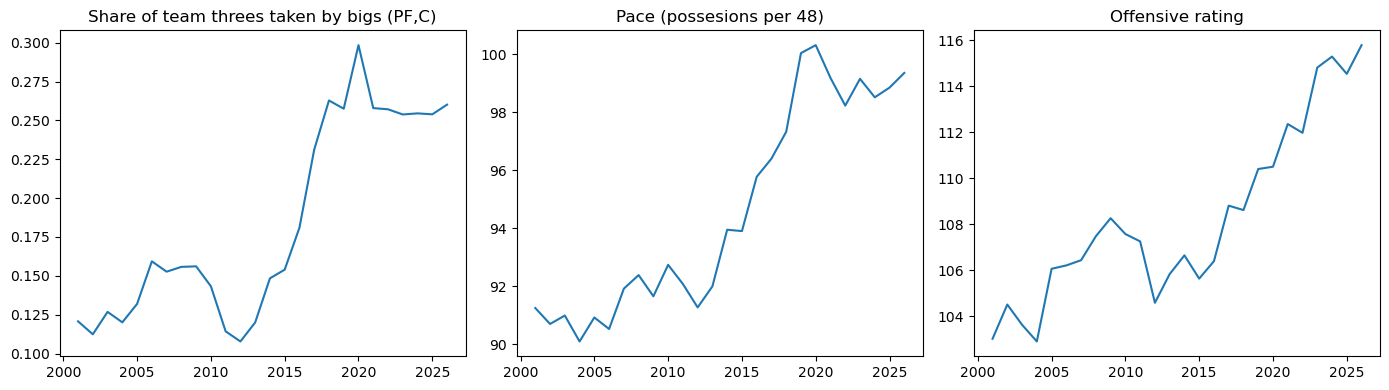

In [14]:
import matplotlib.pyplot as plt

yearly = team.groupby('season')[['big_3pa_share', 'pace', 'o_rtg']].mean()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(yearly.index, yearly['big_3pa_share'])
ax[0].set_title('Share of team threes taken by bigs (PF,C)')

ax[1].plot(yearly.index, yearly['pace'])
ax[1].set_title('Pace (possesions per 48)')

ax[2].plot(yearly.index, yearly['o_rtg'])
ax[2].set_title('Offensive rating')
plt.tight_layout()
plt.savefig('Chart1_trends.png', dpi=150)
plt.show()

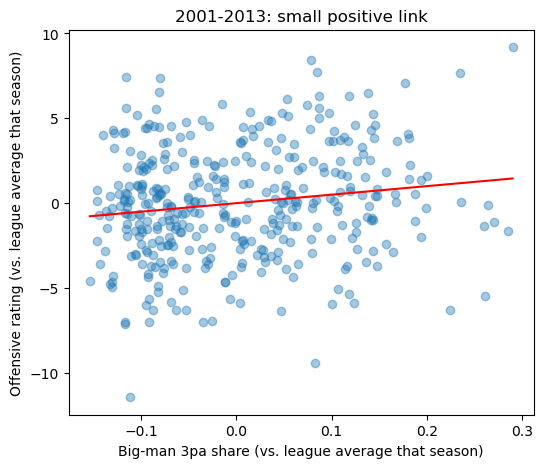

In [15]:
import numpy as np

early = adj[adj['season'] <= 2013]
x = early['big_3pa_share']
y = early['o_rtg']
plt.figure(figsize=(6, 5))
plt.scatter(x, y, alpha=0.4)
slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
plt.plot(xs, slope * xs + intercept, color='red')

plt.xlabel('Big-man 3pa share (vs. league average that season)')
plt.ylabel('Offensive rating (vs. league average that season)')
plt.title('2001-2013: small positive link')
plt.savefig('Chart2_early_scatter.png', dpi=150)
plt.show()